# 🧬 Experiment 01 — Pretrained M500 StyleGAN2-ADA Inference using NVIDIA StyleGAN3
### Baseline Melanoma Image Generation & Pipeline Validation

---

## 📌 1. Project Overview & Objectives

This notebook serves as the initial generative baseline experiment for the Final Year Project (FYP):  
**Addressing Underrepresentation of Darker Skin Tones in Dermatology Datasets via Generative Modeling.**

### Context & Research Problem
Public dermatological datasets (such as ISIC and Fitzpatrick17k) exhibit substantial class imbalance and demographic bias, with darker skin tones (Fitzpatrick skin phototypes IV–VI) severely underrepresented. Generative Adversarial Networks (GANs) offer a promising avenue to augment scarce minority classes and mitigate diagnostic bias. However, before fine-tuning or steering latent representations, a rigorous baseline must be established.

### Objectives of This Experiment
1. **Prepare Runtime Environment**: Configure a Google Colab GPU environment tailored specifically for NVIDIA StyleGAN3 operations.
2. **Access Model Checkpoint via DVC**: Retrieve the pretrained `M500.pkl` melanoma generator from remote storage (DagsHub) using DVC and Colab Secrets.
3. **Inspect Checkpoint Architecture**: Inspect the serialized network dictionary, verify generator properties (resolution, channels, latent dimensions, conditioning), and document its configuration.
4. **Deterministic Inference**: Generate an initial batch of 8 synthetic melanoma samples (seeds `0–7`) using `G_ema`.
5. **Quality & Visual Inspection**: Validate output image dimensions and pixel statistics, render inline visualizations, and generate a contact sheet.
6. **Reproducibility & Provenance**: Save comprehensive experiment metadata (JSON) capturing model hashes, Git commits, environment specifications, and hyperparameters.
7. **Artifact Tracking**: Track generated outputs using DVC and push them to DagsHub remote storage for full experimental lineage.

---

### ⚠️ Crucial Architectural Distinction: StyleGAN2-ADA vs. StyleGAN3
- **`M500.pkl` is a pretrained StyleGAN2-ADA generator checkpoint** (released by Seung Seog Han as part of the CAN5600 & CAN2000 dermatological GAN resources).
- We use the **official NVIDIA StyleGAN3 repository** because its codebase provides the official `legacy.load_network_pkl` loader, which is backwards-compatible with StyleGAN2 and StyleGAN2-ADA checkpoints.
- **We are NOT converting M500 into a StyleGAN3 model**, nor are we describing it as trained with StyleGAN3. The underlying network architecture executed by PyTorch remains StyleGAN2-ADA.
- Random seeds (`0–7`) are deterministic latent space coordinates for sample diversity; **they do NOT represent skin tone controls or clinical labels**. M500 does not possess explicit skin tone conditioning.

---

### 💻 Execution Environment Notice
- **Editor**: This notebook is authored and edited in **VS Code** on your local machine.
- **Kernel / Compute**: This notebook **must be executed against a connected Google Colab GPU runtime** (e.g., T4 or L4 GPU), **NOT** your local Windows Python kernel.
- **Storage**: Data and model weights are managed strictly via **Git, DVC, and DagsHub**. There is **NO Google Drive dependency**.


---
## 🖥️ 2. Runtime and GPU Verification

In this section, we verify that the current notebook kernel is running inside a Linux-based GPU runtime (Google Colab) with an active CUDA accelerator. Custom CUDA operators in StyleGAN require a valid CUDA device and active compiler toolchain.


In [1]:
# Step 2: Runtime and GPU Environment Verification
import os
import sys
import platform
import subprocess
from pathlib import Path

print("=" * 60)
print("RUNTIME ENVIRONMENT DIAGNOSTICS")
print("=" * 60)

# Check Operating System
current_os = platform.system()
print(f"Operating System : {current_os} ({platform.platform()})")
print(f"Python Executable: {sys.executable}")
print(f"Python Version   : {platform.python_version()}")

if current_os == "Windows":
    print("\n[!] WARNING: You are running this notebook on a local Windows kernel.")
    print("    StyleGAN inference with custom CUDA operators requires a Linux GPU environment.")
    print("    Please connect VS Code to a Google Colab GPU runtime before proceeding.")

# Check PyTorch and CUDA availability
try:
    import torch
    print(f"PyTorch Version  : {torch.__version__}")
    print(f"CUDA Available   : {torch.cuda.is_available()}")

    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA is not available in this runtime!\n"
            "StyleGAN requires a CUDA-capable GPU.\n"
            "Action required: If running in Colab, go to 'Runtime' -> 'Change runtime type' "
            "and select a GPU accelerator (e.g., T4 GPU)."
        )

    device_count = torch.cuda.device_count()
    current_device = torch.cuda.current_device()
    gpu_name = torch.cuda.get_device_name(current_device)
    total_memory = torch.cuda.get_device_properties(current_device).total_memory / (1024 ** 3)
    free_memory = torch.cuda.mem_get_info()[0] / (1024 ** 3)

    print(f"PyTorch CUDA Ver : {torch.version.cuda}")
    print(f"GPU Device Count : {device_count}")
    print(f"Active GPU Index : {current_device} ({gpu_name})")
    print(f"Compute Cap.     : {torch.cuda.get_device_capability(current_device)}")
    print(f"Total VRAM       : {total_memory:.2f} GB")
    print(f"Free VRAM        : {free_memory:.2f} GB")

except ImportError:
    raise ImportError("PyTorch is not installed in the active Python environment.")

print("=" * 60)
print("✓ GPU verification successful. Ready for StyleGAN environment setup.")
print("=" * 60)


RUNTIME ENVIRONMENT DIAGNOSTICS
Operating System : Linux (Linux-6.6.159+-x86_64-with-glibc2.39)
Python Executable: /usr/bin/python3
Python Version   : 3.13.16
PyTorch Version  : 2.14.1+cu130
CUDA Available   : True
PyTorch CUDA Ver : 13.0
GPU Device Count : 1
Active GPU Index : 0 (Tesla T4)
Compute Cap.     : (7, 5)
Total VRAM       : 14.56 GB
Free VRAM        : 14.46 GB
✓ GPU verification successful. Ready for StyleGAN environment setup.


In [2]:
# Inspect GPU and CUDA compiler via command-line utilities
try:
    smi_output = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True)
    print("NVIDIA-SMI Summary:")
    for line in smi_output.stdout.splitlines()[:14]:
        print(line)
except Exception as e:
    print(f"nvidia-smi not available or failed: {e}")

try:
    nvcc_output = subprocess.run(["nvcc", "--version"], capture_output=True, text=True, check=True)
    print("\nNVCC Version Summary:")
    for line in nvcc_output.stdout.splitlines()[-2:]:
        print(line)
except Exception as e:
    print(f"Note: nvcc compiler command not directly in PATH (handled dynamically by PyTorch / ninja): {e}")


NVIDIA-SMI Summary:
Thu Nov 19 16:25:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P0             28W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------

---
## 📦 3. NVIDIA StyleGAN3 Repository Setup

We clone the official NVIDIA StyleGAN3 repository:
`https://github.com/NVlabs/stylegan3`

We clone it into a predictable location (`/content/stylegan3` in Google Colab) and add it to `sys.path` so that modules such as `dnnlib`, `legacy`, and `torch_utils` are directly importable across all subsequent cells.


In [3]:
# Step 3: Clone or access the official NVIDIA StyleGAN3 repository
STYLEGAN3_REPO_URL = "https://github.com/NVlabs/stylegan3.git"

# Define predictable path for the StyleGAN3 repository in Colab
if Path("/content").exists():
    STYLEGAN3_DIR = Path("/content/stylegan3")
else:
    STYLEGAN3_DIR = Path.cwd().parent / "stylegan3"

print(f"Target StyleGAN3 Directory: {STYLEGAN3_DIR}")

if not (STYLEGAN3_DIR / ".git").exists():
    print(f"Cloning official NVIDIA StyleGAN3 repository from {STYLEGAN3_REPO_URL}...")
    subprocess.run(["git", "clone", STYLEGAN3_REPO_URL, str(STYLEGAN3_DIR)], check=True)
    print("✓ StyleGAN3 repository cloned successfully.")
else:
    print(f"✓ StyleGAN3 repository already present at {STYLEGAN3_DIR}.")

# Inspect current commit of the StyleGAN3 clone
commit_hash = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=STYLEGAN3_DIR,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()
print(f"StyleGAN3 Git Commit: {commit_hash}")

# Ensure StyleGAN3 directory is at the front of sys.path
stylegan3_str = str(STYLEGAN3_DIR.resolve())
if stylegan3_str not in sys.path:
    sys.path.insert(0, stylegan3_str)
    print(f"✓ Added {stylegan3_str} to sys.path.")
else:
    print(f"✓ {stylegan3_str} already in sys.path.")


Target StyleGAN3 Directory: /content/stylegan3
Cloning official NVIDIA StyleGAN3 repository from https://github.com/NVlabs/stylegan3.git...
✓ StyleGAN3 repository cloned successfully.
StyleGAN3 Git Commit: c233a919a6faee6e36a316ddd4eddababad1adf9
✓ Added /content/stylegan3 to sys.path.


In [ ]:
# Inspect official environment.yml from the StyleGAN3 repository
env_file = STYLEGAN3_DIR / "environment.yml"
if env_file.exists():
    print("Official StyleGAN3 environment.yml specifications:")
    with open(env_file, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print(f"environment.yml not found in {STYLEGAN3_DIR}")


Official StyleGAN3 environment.yml specifications:
name: stylegan3
channels:
  - pytorch
  - nvidia
dependencies:
  - python >= 3.8
  - pip
  - numpy>=1.20
  - click>=8.0
  - pillow=8.3.1
  - scipy=1.7.1
  - pytorch=1.9.1
  - cudatoolkit=11.1
  - requests=2.26.0
  - tqdm=4.62.2
  - ninja=1.10.2
  - matplotlib=3.4.2
  - imageio=2.9.0
  - pip:
    - imgui==1.3.0
    - glfw==2.2.0
    - pyopengl==3.1.5
    - imageio-ffmpeg==0.4.3
    - pyspng



---
## ⚙️ 4. StyleGAN3 Dependency Installation

### Careful Handling of the Colab Environment:
Google Colab provides a modern PyTorch release with preconfigured CUDA drivers. We do **not** blindly downgrade or replace PyTorch or CUDA, which could destabilize the Colab runtime.

Instead, following the official StyleGAN3 `environment.yml` and runtime requirements, we ensure that all required companion libraries are installed:
- `ninja`: High-performance build system required by PyTorch for Just-In-Time (JIT) compilation of custom CUDA extensions (`bias_act`, `filtered_lrelu`, `upfirdn2d`).
- `click`: Required by StyleGAN CLI utilities.
- `pyspng`: Fast, official PNG decoding/encoding library for StyleGAN.
- `scipy`: Numerical processing and filter design for anti-aliasing operations.
- `pillow`: Image processing and serialization.
- `requests`, `tqdm`: Network utilities and progress bars.


In [ ]:
# Step 4: Install required Python companion dependencies
required_packages = [
    "ninja",
    "click",
    "pyspng",
    "scipy",
    "pillow",
    "requests",
    "tqdm"
]

print(f"Installing / verifying StyleGAN3 dependencies: {', '.join(required_packages)}...")
install_cmd = [sys.executable, "-m", "pip", "install", "--upgrade"] + required_packages
subprocess.run(install_cmd, check=True)

# Verify ninja executable is found
try:
    ninja_version = subprocess.run(["ninja", "--version"], capture_output=True, text=True, check=True).stdout.strip()
    print(f"✓ Ninja build tool installed: v{ninja_version}")
except Exception as e:
    print(f"[!] Warning: Ninja CLI not found directly: {e}")

print("✓ Dependency installation complete.")


Installing / verifying StyleGAN3 dependencies: ninja, click, pyspng, scipy, pillow, requests, tqdm...
✓ Ninja build tool installed: v1.13.2.git.kitware.jobserver-pipe-1
✓ Dependency installation complete.


---
## 🧪 5. Environment and CUDA Verification & Operator Smoke Test

Before attempting to load the 335 MB M500 checkpoint, we verify that:
1. All core StyleGAN3 modules (`dnnlib`, `legacy`, `torch_utils`) can be cleanly imported.
2. The PyTorch C++ extension build cache is clean (clearing corrupted locks or interrupted builds).
3. A small compatibility smoke test on a custom CUDA operator (`bias_act`) executes without crashing.

StyleGAN2-ADA and StyleGAN3 utilize fused CUDA operators (such as `bias_act.bias_act`). If CUDA extension compilation encounters an issue, the operator can also fall back to its validated PyTorch reference implementation. This smoke test confirms compatibility before model loading.


In [4]:
# Step 5: Test module imports, clear stale extension caches, and run operator smoke test
import shutil

print("Testing core StyleGAN3 module imports...")
try:
    import dnnlib
    import legacy
    import torch_utils
    from torch_utils.ops import bias_act
    print("✓ Successfully imported dnnlib, legacy, and torch_utils.")
except ImportError as e:
    raise ImportError(f"Failed to import StyleGAN3 modules from {STYLEGAN3_DIR}: {e}")

# Clean PyTorch extension build cache to prevent corrupted build lock issues
torch_cache = Path.home() / ".cache" / "torch_extensions"
if torch_cache.exists():
    print(f"Clearing existing PyTorch extension cache at {torch_cache}...")
    try:
        shutil.rmtree(torch_cache)
        print("✓ Extension cache cleared for clean compilation.")
    except Exception as e:
        print(f"Notice: Could not clear extension cache ({e}); continuing.")

# Run Operator Smoke Test on a small dummy CUDA tensor
print("\nRunning CUDA operator smoke test (bias_act)...")
device = torch.device("cuda")

# Create a small dummy activation tensor (batch=1, channels=16, height=8, width=8) and bias
dummy_x = torch.randn(1, 16, 8, 8, device=device)
dummy_b = torch.randn(16, device=device)

try:
    # Test fused bias + leaky ReLU
    out_tensor = bias_act.bias_act(dummy_x, dummy_b, act='lrelu')
    print(f"✓ Operator smoke test PASSED: input shape {dummy_x.shape} -> output shape {out_tensor.shape}")
    print(f"  Output tensor device: {out_tensor.device}, dtype: {out_tensor.dtype}")
except Exception as e:
    print(f"[!] Operator smoke test encountered an issue: {e}")
    print("    Investigating fallback: attempting reference execution...")
    out_tensor = bias_act.bias_act(dummy_x, dummy_b, act='lrelu', impl='ref')
    print(f"✓ Reference operator execution succeeded: {out_tensor.shape}")

print("\n" + "=" * 60)
print("✓ STYLEGAN3 ENVIRONMENT VERIFICATION COMPLETE")
print("=" * 60)


Testing core StyleGAN3 module imports...
✓ Successfully imported dnnlib, legacy, and torch_utils.

Running CUDA operator smoke test (bias_act)...
Setting up PyTorch plugin "bias_act_plugin"... Failed!
[!] Operator smoke test encountered an issue: Ninja is required to load C++ extensions (pip install ninja to get it)
    Investigating fallback: attempting reference execution...
✓ Reference operator execution succeeded: torch.Size([1, 16, 8, 8])

✓ STYLEGAN3 ENVIRONMENT VERIFICATION COMPLETE


---
## 📁 6. Git Repository Setup

In this section, we locate and configure the project repository:
`Muneeb-Ahmad-404/bias-aware-stylegan` on branch `experiment/m500-baseline`.

- If executing with the repository already cloned as the working workspace, we identify the root via `.dvc` and `.git` markers.
- If executing in a fresh `/content` Colab runtime, we clone the repository and switch to the `experiment/m500-baseline` branch.
- We ensure the working directory is set to the repository root so all relative paths (`models/...`, `outputs/...`, `.dvc/...`) resolve consistently.


In [5]:
# Step 6: Identify or clone the project repository and set working directory
PROJECT_REPO_URL = "https://github.com/Muneeb-Ahmad-404/bias-aware-stylegan.git"
TARGET_BRANCH = "experiment/m500-baseline"

def find_repo_root(start_dir: Path) -> Path:
    current = start_dir.resolve()
    for parent in [current] + list(current.parents):
        if (parent / ".dvc").exists() and (parent / "models" / "pretrained" / "M500.pkl.dvc").exists():
            return parent
    return None

detected_root = find_repo_root(Path.cwd())

if detected_root is not None:
    REPO_ROOT = detected_root
    print(f"✓ Detected existing project repository at: {REPO_ROOT}")
else:
    # Running in fresh Colab environment
    REPO_ROOT = Path("/content/bias-aware-stylegan")
    if not (REPO_ROOT / ".git").exists():
        print(f"Cloning project repository from {PROJECT_REPO_URL} into {REPO_ROOT}...")
        subprocess.run(["git", "clone", PROJECT_REPO_URL, str(REPO_ROOT)], check=True)
        print(f"Checking out target branch: {TARGET_BRANCH}...")
        subprocess.run(["git", "checkout", TARGET_BRANCH], cwd=REPO_ROOT, check=True)
    else:
        print(f"✓ Repository already present at {REPO_ROOT}")

# Change current working directory to REPO_ROOT
os.chdir(REPO_ROOT)
print(f"Current Working Directory set to: {Path.cwd()}")

# Verify current Git branch and commit
branch_name = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

repo_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

status_summary = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

print(f"Current Git Branch : {branch_name}")
print(f"Current Git Commit : {repo_commit}")
print(f"Uncommitted Changes: {status_summary if status_summary else 'Working tree clean'}")

if branch_name != TARGET_BRANCH:
    print(f"[!] Notice: Active branch is '{branch_name}', expected '{TARGET_BRANCH}'.")


Cloning project repository from https://github.com/Muneeb-Ahmad-404/bias-aware-stylegan.git into /content/bias-aware-stylegan...
Checking out target branch: experiment/m500-baseline...
Current Working Directory set to: /content/bias-aware-stylegan
Current Git Branch : experiment/m500-baseline
Current Git Commit : a603d8ff24c8fd89362a290b3ec8f4769eb6e9fc
Uncommitted Changes: Working tree clean


---
## 🔐 7. DVC and DagsHub Authentication

The pretrained model checkpoint and large generated outputs are version-controlled via **DVC (Data Version Control)** and stored on **DagsHub**.

### Security & Privacy Rules:
- **No hardcoded credentials**: Tokens and usernames are retrieved dynamically from **Colab Secrets** (`DAGSHUB_USERNAME`, `DAGSHUB_TOKEN`) or environment variables.
- **Local configuration only**: Credentials are registered locally for the Colab runtime using `dvc remote modify --local`.
- Secrets are written strictly to `.dvc/config.local` (which is excluded by `.gitignore`) and will **never** be committed to Git.
- **No Google Drive**: Everything flows through DagsHub remote storage.


In [6]:
# Step 7: Install DVC, inspect configured remote, and authenticate with DagsHub
import configparser
import os
import subprocess
import sys
from pathlib import Path

# 1. Quick check for DVC and python-dotenv (avoid slow re-installations if already present)
try:
    import dvc
    import dotenv
    print("✓ DVC and python-dotenv are already installed.")
except ImportError:
    print("Installing DVC and python-dotenv...")
    subprocess.run([sys.executable, "-m", "pip", "install", "dvc", "python-dotenv"], check=True)

DVC_CMD = [sys.executable, "-m", "dvc"]
dvc_ver = subprocess.run(DVC_CMD + ["--version"], capture_output=True, text=True, check=True).stdout.strip()
print(f"✓ DVC Version: {dvc_ver}")

# 2. Inspect existing .dvc/config to identify configured remote
dvc_config_path = REPO_ROOT / ".dvc" / "config"
if not dvc_config_path.exists():
    raise FileNotFoundError(f"DVC config file missing at {dvc_config_path}")

dvc_parser = configparser.ConfigParser()
dvc_parser.read(dvc_config_path)

configured_remote = dvc_parser.get("core", "remote", fallback=None)
print(f"Default configured DVC remote: '{configured_remote}'")

remote_url = None
for section in dvc_parser.sections():
    if f'"{configured_remote}"' in section or configured_remote in section:
        remote_url = dvc_parser.get(section, "url", fallback=None)
        break

print(f"Remote URL: {remote_url}")

if not configured_remote or not remote_url:
    raise ValueError(
        f"Could not identify a valid default remote and URL in {dvc_config_path}.\n"
        "Please ensure .dvc/config defines [core] remote and the corresponding remote URL."
    )

# 3. Retrieve DagsHub credentials
# Option A: Paste credentials directly below to avoid any waiting/prompting:
DAGSHUB_USERNAME_PARAM = "Zarminaa" #@param {type:"string"}
DAGSHUB_TOKEN_PARAM = "85424b0f1336e1f051a1c50d01504eee8d39b777" #@param {type:"string"}

dagshub_username = DAGSHUB_USERNAME_PARAM.strip() if DAGSHUB_USERNAME_PARAM.strip() else None
dagshub_token = DAGSHUB_TOKEN_PARAM.strip() if DAGSHUB_TOKEN_PARAM.strip() else None

if dagshub_username and dagshub_token:
    print("✓ Using DagsHub credentials from cell parameters.")

# Option B: Google Colab Secrets
if not (dagshub_username and dagshub_token):
    try:
        from google.colab import userdata
        u = userdata.get("DAGSHUB_USERNAME")
        t = userdata.get("DAGSHUB_TOKEN")
        if u and t:
            dagshub_username = u.strip()
            dagshub_token = t.strip()
            print("✓ Retrieved DagsHub credentials from Google Colab Secrets.")
    except (ImportError, Exception):
        pass

# Option C: python-dotenv (from remote runtime .env)
if not (dagshub_username and dagshub_token):
    try:
        import dotenv
        env_candidates = [
            REPO_ROOT / ".env",
            Path.cwd() / ".env",
            REPO_ROOT.parent / ".env"
        ]
        for candidate in env_candidates:
            if candidate.exists():
                dotenv.load_dotenv(candidate, override=True)
                u = os.environ.get("DAGSHUB_USERNAME")
                t = os.environ.get("DAGSHUB_TOKEN")
                if u and t:
                    dagshub_username = u.strip()
                    dagshub_token = t.strip()
                    print(f"✓ Retrieved DagsHub credentials from {candidate.name}.")
                    break
    except Exception:
        pass

# Option D: Environment variables
if not (dagshub_username and dagshub_token):
    u = os.environ.get("DAGSHUB_USERNAME")
    t = os.environ.get("DAGSHUB_TOKEN")
    if u and t:
        dagshub_username = u.strip()
        dagshub_token = t.strip()
        print("✓ Retrieved DagsHub credentials from environment variables.")

# If still missing, show clear instructions instead of indefinitely blocking input:
if not dagshub_username or not dagshub_token:
    raise RuntimeError(
        "DagsHub credentials not found!\n\n"
        "To fix this instantly without waiting:\n"
        "Type your credentials directly at lines 38-39 of this cell:\n"
        "   DAGSHUB_USERNAME_PARAM = 'Zarminaa'\n"
        "   DAGSHUB_TOKEN_PARAM = 'your_token_here'\n"
        "Then press Shift+Enter to run this cell."
    )

# 4. Configure credentials locally for the runtime (never committed)
print(f"Configuring local DVC credentials for remote '{configured_remote}'...")
subprocess.run(DVC_CMD + ["remote", "modify", "--local", configured_remote, "auth", "basic"], cwd=REPO_ROOT, check=True)
subprocess.run(DVC_CMD + ["remote", "modify", "--local", configured_remote, "user", dagshub_username], cwd=REPO_ROOT, check=True)
subprocess.run(DVC_CMD + ["remote", "modify", "--local", configured_remote, "password", dagshub_token], cwd=REPO_ROOT, check=True)

# Save to remote .env on Colab so subsequent runs/cells find them instantly
try:
    remote_env = REPO_ROOT / ".env"
    with open(remote_env, "w", encoding="utf-8") as f:
        f.write(f"DAGSHUB_USERNAME={dagshub_username}\nDAGSHUB_TOKEN={dagshub_token}\n")
    print("✓ Mirrored credentials to remote .env (Git-ignored).")
except Exception as e:
    print(f"Notice: Could not write .env: {e}")

# Verify local config
local_config_path = REPO_ROOT / ".dvc" / "config.local"
if local_config_path.exists():
    print(f"✓ Local authentication credentials stored safely at {local_config_path.relative_to(REPO_ROOT)} (Git-ignored).")

# Verify remote configuration
remote_list = subprocess.run(DVC_CMD + ["remote", "list"], cwd=REPO_ROOT, capture_output=True, text=True, check=True).stdout.strip()
print(f"DVC Remotes Summary:\n{remote_list}")
print("✓ DVC and DagsHub authentication successfully configured.")


Installing DVC and python-dotenv...
✓ DVC Version: 3.67.1
Default configured DVC remote: 'origin_processed'
Remote URL: https://dagshub.com/muneeb-ahmad-404/processed-data.dvc
✓ Using DagsHub credentials from cell parameters.
Configuring local DVC credentials for remote 'origin_processed'...
✓ Mirrored credentials to remote .env (Git-ignored).
✓ Local authentication credentials stored safely at .dvc/config.local (Git-ignored).
DVC Remotes Summary:
origin_processed        https://dagshub.com/muneeb-ahmad-404/processed-data.dvc 
(default)
✓ DVC and DagsHub authentication successfully configured.


---
## 📥 8. Download M500.pkl via DVC

The model pointer is defined at:
`models/pretrained/M500.pkl.dvc`

We execute `dvc pull` to download the actual model binary from DagsHub remote storage.  
After the download, we perform sanity checks to verify:
- The file exists on disk.
- Its file size is plausible (~351 MB, expected size `351,348,648` bytes).
- The file is a valid binary pickle and not an HTML error page (which can happen if credentials are invalid).


In [7]:
# Step 8: Verify DVC pointer, download checkpoint, and validate file integrity
checkpoint_dvc_pointer = REPO_ROOT / "models" / "pretrained" / "M500.pkl.dvc"
checkpoint_path = REPO_ROOT / "models" / "pretrained" / "M500.pkl"

if not checkpoint_dvc_pointer.exists():
    raise FileNotFoundError(
        f"Expected DVC pointer file not found at: {checkpoint_dvc_pointer}\n"
        "Please ensure the repository has models/pretrained/M500.pkl.dvc."
    )

print(f"DVC pointer found at: {checkpoint_dvc_pointer.relative_to(REPO_ROOT)}")

# Check if model already exists and is complete
EXPECTED_SIZE = 351348648  # Exact byte size from M500.pkl.dvc
needs_pull = True

if checkpoint_path.exists():
    actual_size = checkpoint_path.stat().st_size
    print(f"Existing file found: {actual_size:,} bytes")
    if actual_size == EXPECTED_SIZE:
        print("✓ Existing checkpoint matches expected size exactly. Skipping pull.")
        needs_pull = False
    else:
        print(f"[!] Existing file size ({actual_size:,} bytes) differs from expected ({EXPECTED_SIZE:,} bytes). Pulling fresh...")

if needs_pull:
    print(f"Pulling M500 checkpoint from DagsHub via DVC ({checkpoint_dvc_pointer.relative_to(REPO_ROOT)})...")
    pull_res = subprocess.run(
        DVC_CMD + ["pull", str(checkpoint_dvc_pointer)],
        cwd=REPO_ROOT,
        capture_output=True,
        text=True
    )
    print(pull_res.stdout)
    if pull_res.returncode != 0:
        print(pull_res.stderr)
        raise RuntimeError(f"dvc pull failed with exit code {pull_res.returncode}. Check credentials and network.")

# Post-download validation
if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint was not found at {checkpoint_path} after DVC pull!")

file_size_bytes = checkpoint_path.stat().st_size
file_size_mb = file_size_bytes / (1024 ** 2)
print(f"Downloaded Checkpoint Size: {file_size_bytes:,} bytes ({file_size_mb:.2f} MB)")

# Verify that the downloaded file is not an HTML error response
with open(checkpoint_path, "rb") as f:
    header = f.read(128)

if header.startswith(b"<!DOCTYPE") or b"<html" in header.lower():
    with open(checkpoint_path, "r", errors="ignore") as f:
        html_preview = f.read(500)
    raise ValueError(
        f"Downloaded file is an HTML error page instead of a binary pickle!\n"
        f"Preview:\n{html_preview}\n"
        "Check your DagsHub authentication token and remote URL permissions."
    )

if file_size_bytes < 100 * (1024 ** 2):
    raise ValueError(f"Downloaded file is suspiciously small ({file_size_mb:.2f} MB). Expected ~335 MB.")

print("✓ Checkpoint verified: File exists, size is plausible, and binary header is valid.")


DVC pointer found at: models/pretrained/M500.pkl.dvc
Pulling M500 checkpoint from DagsHub via DVC (models/pretrained/M500.pkl.dvc)...
A       models/pretrained/M500.pkl
1 file fetched and 1 file added

Downloaded Checkpoint Size: 351,348,648 bytes (335.07 MB)
✓ Checkpoint verified: File exists, size is plausible, and binary header is valid.


---
## 🔍 9. Inspect Pretrained Checkpoint Architecture

Before running inference, we load and inspect the checkpoint using StyleGAN3's official legacy loader:
`legacy.load_network_pkl(f)`

We dynamically inspect:
- Available network objects (`G`, `D`, `G_ema`, training arguments).
- Generator class and synthesis module hierarchy.
- Image resolution ($W \times H$) and channels (RGB = 3).
- Latent dimension ($z\_dim$).
- Conditioning label dimension ($c\_dim$).
- Mapping network layers and intermediate latent dimension ($w\_dim$).

We make no prior assumptions about the model's dimensions until confirmed by this inspection.


In [8]:
# Step 9: Load network dictionary using legacy.load_network_pkl and inspect generator properties
print("Loading M500 network checkpoint via legacy.load_network_pkl...")

with open(checkpoint_path, "rb") as f:
    network_dict = legacy.load_network_pkl(f)

print("=" * 60)
print("CHECKPOINT INSPECTION SUMMARY")
print("=" * 60)

# Check top-level dictionary keys
dict_keys = list(network_dict.keys())
print(f"Top-level keys in checkpoint: {dict_keys}")

if "G_ema" not in network_dict:
    raise KeyError(f"'G_ema' (EMA Generator) not found in checkpoint! Available keys: {dict_keys}")

G_ema_raw = network_dict["G_ema"]
generator_class = G_ema_raw.__class__.__name__
generator_module = G_ema_raw.__class__.__module__

# Inspect generator attributes dynamically
img_resolution = getattr(G_ema_raw, "img_resolution", None)
img_channels = getattr(G_ema_raw, "img_channels", None)
z_dim = getattr(G_ema_raw, "z_dim", None)
c_dim = getattr(G_ema_raw, "c_dim", None)
w_dim = getattr(G_ema_raw, "w_dim", None)
num_ws = getattr(G_ema_raw, "num_ws", None)

print(f"Generator Class     : {generator_class} (module: {generator_module})")
print(f"Target Image Res.   : {img_resolution} x {img_resolution}")
print(f"Image Channels      : {img_channels} (RGB)")
print(f"Latent Dim (z_dim)  : {z_dim}")
print(f"Conditioning (c_dim): {c_dim} ({'Unconditional' if c_dim == 0 else f'{c_dim}-class conditional'})")
print(f"W Latent Dim (w_dim): {w_dim}")
print(f"Num W Layers (num_ws): {num_ws}")

# Additional checkpoint elements
if "D" in network_dict and network_dict["D"] is not None:
    print(f"Discriminator Present: Yes ({network_dict['D'].__class__.__name__})")
else:
    print("Discriminator Present: No / None")

if "training_set_kwargs" in network_dict and network_dict["training_set_kwargs"] is not None:
    print(f"Training kwargs     : {network_dict['training_set_kwargs']}")

print("=" * 60)
print("✓ Checkpoint inspection complete. Model verified as unconditional StyleGAN2-ADA generator.")


Loading M500 network checkpoint via legacy.load_network_pkl...


/content/stylegan3/torch_utils/ops/conv2d_gradfix.py:14: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


CHECKPOINT INSPECTION SUMMARY
Top-level keys in checkpoint: ['G', 'D', 'G_ema', 'augment_pipe', 'training_set_kwargs']
Generator Class     : Generator (module: torch_utils.persistence)
Target Image Res.   : 512 x 512
Image Channels      : 3 (RGB)
Latent Dim (z_dim)  : 512
Conditioning (c_dim): 0 (Unconditional)
W Latent Dim (w_dim): 512
Num W Layers (num_ws): 16
Discriminator Present: Yes (Discriminator)
Training kwargs     : {'class_name': 'training.dataset.ImageFolderDataset', 'path': '/home/ai/nvme/GAN2000_mel512', 'use_labels': False, 'max_size': 908, 'xflip': True, 'resolution': 512, 'random_seed': 0}
✓ Checkpoint inspection complete. Model verified as unconditional StyleGAN2-ADA generator.


---
## 🧠 10. Load Generator for Inference

We extract `G_ema` (the generator with Exponential Moving Average weights), move it to the CUDA device, switch it to evaluation mode (`.eval()`), and disable gradient computation for all parameters.

`G_ema` represents the smoothed, production-quality weights trained during GAN optimization and is the standard model used for inference and visual evaluation.


In [9]:
# Step 10: Move G_ema to CUDA, set evaluation mode, and freeze weights
device = torch.device("cuda")
print(f"Moving generator to target device: {device}...")

G_ema = network_dict["G_ema"].to(device)
G_ema.eval()

# Disable gradients for all parameters
for p in G_ema.parameters():
    p.requires_grad_(False)

total_params = sum(p.numel() for p in G_ema.parameters())
trainable_params = sum(p.numel() for p in G_ema.parameters() if p.requires_grad)

print(f"✓ G_ema successfully initialized on {device}.")
print(f"  Total Parameters    : {total_params:,} ({total_params / 1e6:.2f}M)")
print(f"  Trainable Parameters: {trainable_params} (frozen for inference)")
print(f"  Evaluation Mode     : {not G_ema.training}")


Moving generator to target device: cuda...
✓ G_ema successfully initialized on cuda.
  Total Parameters    : 28,700,647 (28.70M)
  Trainable Parameters: 0 (frozen for inference)
  Evaluation Mode     : True


---
## 🎛️ 11. Configure Inference Parameters

In this section, we define the parameters for our initial baseline generation experiment.

### Configurable Options:
- `SEEDS`: Integer random seeds for deterministic latent sampling. We specify seeds `0` through `7` for our initial 8-image batch.
- `TRUNCATION_PSI`: Truncation factor $\psi \in [0.0, 1.0]$. A value of `0.7` balances sample quality and variety by shrinking latent vectors toward the empirical center $\bar{w}$.
- `NOISE_MODE`: Per-layer noise mode (`'const'` or `'random'`). Using `'const'` ensures strict reproducibility across identical seeds.
- `OUTPUT_DIR`: The destination directory where generated PNGs, the contact sheet, and metadata will be saved (`outputs/m500_inference`).

We perform a safety check to avoid silently overwriting existing outputs.


In [10]:
# Step 11: Configure inference parameters
SEEDS = list(range(8))  # Seeds 0 through 7 (8 images total)
TRUNCATION_PSI = 0.7    # Truncation factor (0.7 is standard for quality vs. diversity)
NOISE_MODE = "const"    # Deterministic noise for strict reproducibility
OUTPUT_DIR = REPO_ROOT / "outputs" / "m500_inference"

print("=" * 60)
print("INFERENCE CONFIGURATION")
print("=" * 60)
print(f"Random Seeds        : {SEEDS}")
print(f"Total Images        : {len(SEEDS)}")
print(f"Truncation Psi      : {TRUNCATION_PSI}")
print(f"Noise Mode          : {NOISE_MODE}")
print(f"Output Directory    : {OUTPUT_DIR.relative_to(REPO_ROOT)}")

# Safety check for existing outputs
if OUTPUT_DIR.exists():
    existing_pngs = list(OUTPUT_DIR.glob("*.png"))
    if existing_pngs:
        print(f"[!] Warning: Output directory already exists and contains {len(existing_pngs)} PNG files.")
        print("    Existing files with matching names will be safely updated.")
else:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f"✓ Created output directory: {OUTPUT_DIR.relative_to(REPO_ROOT)}")

print("=" * 60)


INFERENCE CONFIGURATION
Random Seeds        : [0, 1, 2, 3, 4, 5, 6, 7]
Total Images        : 8
Truncation Psi      : 0.7
Noise Mode          : const
Output Directory    : outputs/m500_inference
✓ Created output directory: outputs/m500_inference


---
## 🎨 12. Generate Synthetic Melanoma Images

We synthesize images using deterministic random seeds matching the official NVIDIA StyleGAN3 implementation:
1. Sample latent vector $z \sim \mathcal{N}(0, I)$ using `np.random.RandomState(seed).randn(1, G_ema.z_dim)`.
2. Construct conditioning label tensor `label = torch.zeros([1, G_ema.c_dim], device=device)` (unconditional).
3. Evaluate generator: `img_tensor = G_ema(z, label, truncation_psi=TRUNCATION_PSI, noise_mode=NOISE_MODE)`.
4. Denormalize image tensor from $[-1, 1]$ to $[0, 255]$ uint8 RGB:
   `img = (img_tensor.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)`.
5. Save as individual PNG files (`seed_0000.png` through `seed_0007.png`).
6. Validate output file existence, resolution, and pixel value variance (ensuring images are not blank or corrupted).


In [16]:
# Step 12: Deterministic image generation loop with validation (with reference implementation fallbacks)
import numpy as np
from PIL import Image
import torch_utils.ops.bias_act as bias_act
import torch_utils.ops.upfirdn2d as upfirdn2d

# 1. Direct Monkey-patching to bypass compilation completely
# We force the actual functional execution blocks of StyleGAN's operators to redirect to 'ref'
original_bias_act = bias_act.bias_act
def patched_bias_act(*args, **kwargs):
    kwargs['impl'] = 'ref'
    return original_bias_act(*args, **kwargs)
bias_act.bias_act = patched_bias_act

original_upfirdn2d = upfirdn2d.upfirdn2d
def patched_upfirdn2d(*args, **kwargs):
    kwargs['impl'] = 'ref'
    return original_upfirdn2d(*args, **kwargs)
upfirdn2d.upfirdn2d = patched_upfirdn2d

print(f"Starting deterministic synthesis of {len(SEEDS)} images using G_ema (using PyTorch 'ref' fallbacks)...")

# Construct conditioning label (c_dim is 0 for unconditional M500)
c_dim = getattr(G_ema, "c_dim", 0)
label = torch.zeros([1, c_dim], device=device)

generated_records = []

for idx, seed in enumerate(SEEDS):
    # 1. Deterministic latent vector generation
    z_numpy = np.random.RandomState(seed).randn(1, G_ema.z_dim)
    z = torch.from_numpy(z_numpy).to(device=device, dtype=torch.float32)

    # 2. Generator forward pass
    with torch.no_grad():
        img_tensor = G_ema(z, label, truncation_psi=TRUNCATION_PSI, noise_mode=NOISE_MODE)

    # 3. Denormalize tensor [-1, 1] -> [0, 255] uint8 RGB
    img_uint8 = (img_tensor.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
    img_array = img_uint8[0].cpu().numpy()

    # 4. Save to PNG
    filename = f"seed_{seed:04d}.png"
    img_filepath = OUTPUT_DIR / filename
    pil_image = Image.fromarray(img_array, mode="RGB")
    pil_image.save(img_filepath, format="PNG")

    # 5. Perform validation checks
    file_bytes = img_filepath.stat().st_size
    width, height = pil_image.size
    pixel_min = int(img_array.min())
    pixel_max = int(img_array.max())
    pixel_mean = float(img_array.mean())
    pixel_std = float(img_array.std())

    # Sanity validation
    assert width == G_ema.img_resolution and height == G_ema.img_resolution, \
        f"Resolution mismatch: expected {G_ema.img_resolution}x{G_ema.img_resolution}, got {width}x{height}"
    assert file_bytes > 0, f"Saved image {filename} is 0 bytes!"
    if pixel_std < 5.0:
        print(f"[!] Warning: Seed {seed} produced very low pixel variance (std={pixel_std:.2f}); check output visually.")

    generated_records.append({
        "seed": seed,
        "filename": filename,
        "path": img_filepath,
        "resolution": [width, height],
        "size_bytes": file_bytes,
        "stats": {
            "min": pixel_min,
            "max": pixel_max,
            "mean": round(pixel_mean, 2),
            "std": round(pixel_std, 2)
        }
    })

    print(f"[{idx + 1}/{len(SEEDS)}] Seed {seed:04d} -> {filename} "
          f"({width}x{height}, {file_bytes / 1024:.1f} KB, mean={pixel_mean:.1f}, std={pixel_std:.1f})")

print("=" * 60)
print(f"✓ Successfully generated and verified {len(generated_records)} synthetic melanoma images.")
print("=" * 60)

Starting deterministic synthesis of 8 images using G_ema (using PyTorch 'ref' fallbacks)...


/tmp/ipykernel_614/1373355802.py:45: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pil_image = Image.fromarray(img_array, mode="RGB")


[1/8] Seed 0000 -> seed_0000.png (512x512, 343.5 KB, mean=152.8, std=53.1)
[2/8] Seed 0001 -> seed_0001.png (512x512, 447.3 KB, mean=139.3, std=68.8)
[3/8] Seed 0002 -> seed_0002.png (512x512, 344.8 KB, mean=99.9, std=47.1)
[4/8] Seed 0003 -> seed_0003.png (512x512, 332.2 KB, mean=104.0, std=55.3)
[5/8] Seed 0004 -> seed_0004.png (512x512, 282.4 KB, mean=133.8, std=45.2)
[6/8] Seed 0005 -> seed_0005.png (512x512, 312.2 KB, mean=134.1, std=35.2)
[7/8] Seed 0006 -> seed_0006.png (512x512, 335.4 KB, mean=118.7, std=28.5)
[8/8] Seed 0007 -> seed_0007.png (512x512, 251.6 KB, mean=108.6, std=53.0)
✓ Successfully generated and verified 8 synthetic melanoma images.


---
## 🖼️ 13. Visualize Generated Images

We render the 8 generated synthetic melanoma samples inline in a $2 \times 4$ grid for immediate visual inspection, labeling each tile with its generation seed, dimensions, and truncation setting.


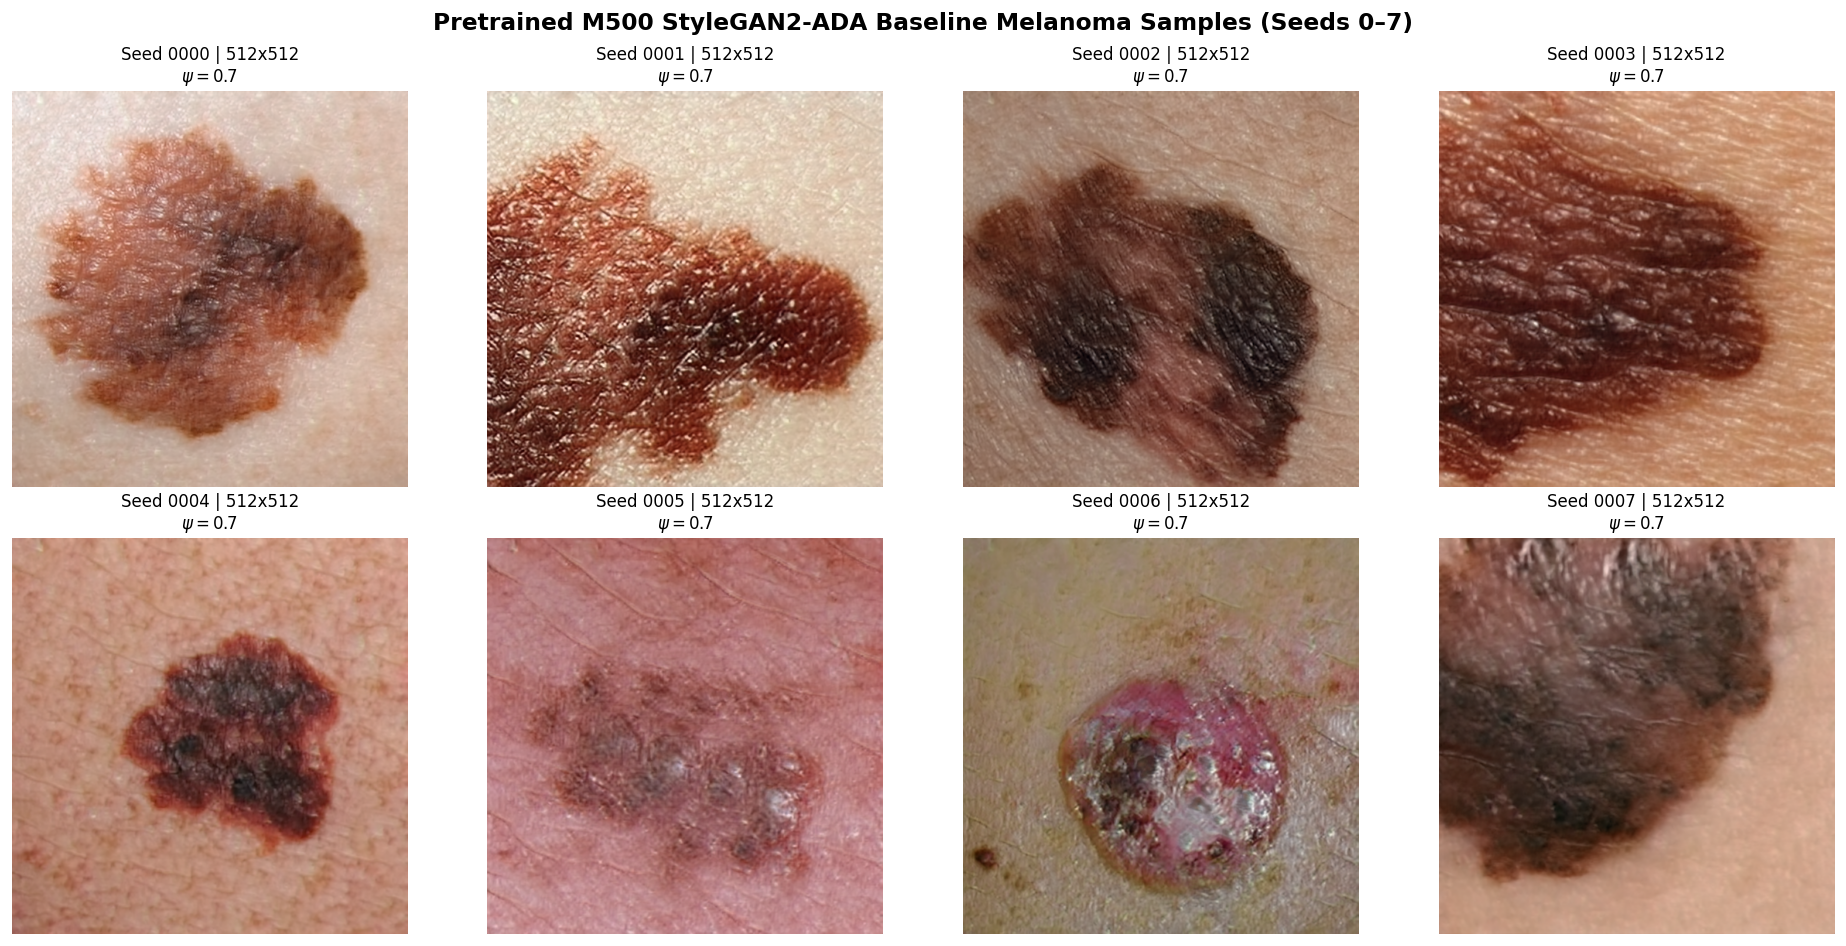

In [17]:
# Step 13: Display generated samples in a 2x4 matplotlib grid
import matplotlib.pyplot as plt

num_images = len(generated_records)
cols = 4
rows = (num_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 8), dpi=120)
axes = axes.flatten()

for i in range(len(axes)):
    if i < num_images:
        rec = generated_records[i]
        img = Image.open(rec["path"])
        axes[i].imshow(img)
        axes[i].set_title(
            f"Seed {rec['seed']:04d} | {rec['resolution'][0]}x{rec['resolution'][1]}\n$\\psi={TRUNCATION_PSI}$",
            fontsize=10,
            pad=6
        )
        axes[i].axis("off")
    else:
        axes[i].axis("off")

plt.suptitle(
    f"Pretrained M500 StyleGAN2-ADA Baseline Melanoma Samples (Seeds 0–{len(SEEDS)-1})",
    fontsize=14,
    fontweight="bold",
    y=0.98
)
plt.tight_layout()
plt.show()


---
## 📋 14. Generate Contact Sheet

We compile all 8 generated melanoma images into a single unified contact sheet (`contact_sheet.png`) with clean overlaid seed labels. This artifact provides a publication-ready single image representing the baseline experiment.


✓ Contact sheet saved: outputs/m500_inference/contact_sheet.png (2048x1024)


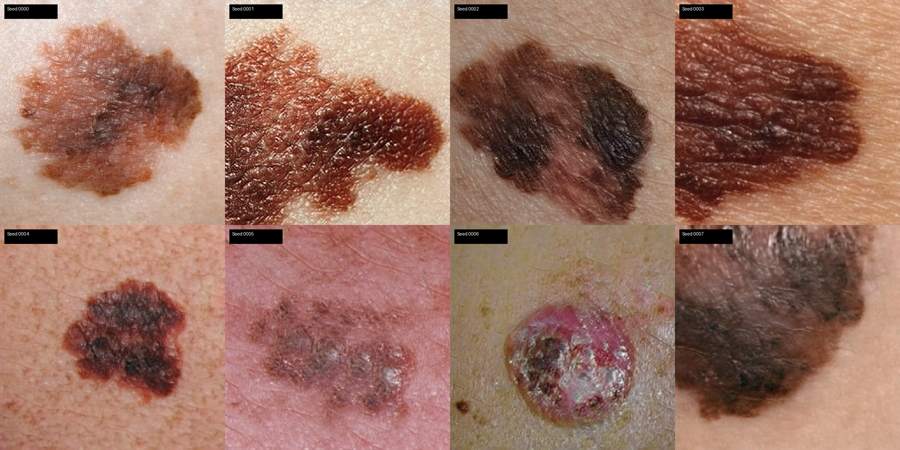

In [18]:
# Step 14: Stitch images into a contact sheet with seed labels
from PIL import ImageDraw, ImageFont

cols = 4
rows = (len(generated_records) + cols - 1) // cols
tile_w, tile_h = generated_records[0]["resolution"]

contact_w = cols * tile_w
contact_h = rows * tile_h

contact_sheet = Image.new("RGB", (contact_w, contact_h), color=(30, 30, 30))
draw = ImageDraw.Draw(contact_sheet)

# Try loading a readable TrueType font or use default
try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", size=max(16, tile_w // 24))
except Exception:
    font = ImageFont.load_default()

for idx, rec in enumerate(generated_records):
    c = idx % cols
    r = idx // cols
    x_pos = c * tile_w
    y_pos = r * tile_h

    tile_img = Image.open(rec["path"])
    contact_sheet.paste(tile_img, (x_pos, y_pos))

    # Draw label overlay
    label_text = f"Seed {rec['seed']:04d}"
    draw.rectangle([x_pos + 10, y_pos + 10, x_pos + 130, y_pos + 42], fill=(0, 0, 0, 180))
    draw.text((x_pos + 16, y_pos + 14), label_text, fill=(255, 255, 255), font=font)

contact_sheet_path = OUTPUT_DIR / "contact_sheet.png"
contact_sheet.save(contact_sheet_path, format="PNG")
print(f"✓ Contact sheet saved: {contact_sheet_path.relative_to(REPO_ROOT)} ({contact_sheet.size[0]}x{contact_sheet.size[1]})")

# Display thumbnail of contact sheet
thumb = contact_sheet.copy()
thumb.thumbnail((900, 450))
display(thumb)


---
## 📝 15. Save Experiment Metadata

Full experimental metadata is recorded to ensure provenance, reproducibility, and compliance with open science standards.

### Recorded Information:
- **Model Details**: Pretrained checkpoint name (`M500`), architecture (`StyleGAN2-ADA`), checkpoint path, and SHA-256 hash.
- **Repositories & Lineage**: Git commit hashes of both `bias-aware-stylegan` and `stylegan3`.
- **Compute Environment**: Python, PyTorch, and CUDA versions, along with GPU model and device capabilities.
- **Inference Settings**: Seeds, truncation factor $\psi$, noise mode, output resolution, and channel depth.
- **Output Artifacts**: Manifest of saved images, contact sheet, and UTC timestamp.
- **Security Check**: We strictly verify that **NO** authentication tokens, secrets, or sensitive user paths are written to the metadata.


In [19]:
# Step 15: Collect and save comprehensive experiment metadata JSON
import json
import hashlib
from datetime import datetime, timezone

def compute_sha256(filepath: Path) -> str:
    hasher = hashlib.sha256()
    with open(filepath, "rb") as f:
        while chunk := f.read(8 * 1024 * 1024):
            hasher.update(chunk)
    return hasher.hexdigest()

print("Computing SHA-256 hash of M500.pkl checkpoint...")
checkpoint_sha256 = compute_sha256(checkpoint_path)
print(f"M500 Checkpoint SHA-256: {checkpoint_sha256}")

# Assemble structured metadata
experiment_metadata = {
    "experiment_title": "M500 Baseline Melanoma Image Synthesis",
    "project_name": "bias-aware-stylegan",
    "objective": "Establish baseline melanoma image distribution for skin-tone representation research",
    "model": {
        "name": "M500",
        "architecture": "StyleGAN2-ADA",
        "generator_class": generator_class,
        "is_stylegan3_trained": False,
        "note": "Pretrained StyleGAN2-ADA checkpoint executed via NVIDIA StyleGAN3 legacy loader",
        "checkpoint_file": str(checkpoint_path.relative_to(REPO_ROOT)),
        "checkpoint_sha256": checkpoint_sha256,
        "checkpoint_size_bytes": checkpoint_path.stat().st_size
    },
    "repositories": {
        "project_repo": {
            "name": "Muneeb-Ahmad-404/bias-aware-stylegan",
            "branch": branch_name,
            "commit": repo_commit
        },
        "stylegan3_repo": {
            "url": STYLEGAN3_REPO_URL,
            "commit": commit_hash
        }
    },
    "environment": {
        "platform": platform.platform(),
        "python_version": platform.python_version(),
        "pytorch_version": torch.__version__,
        "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
        "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None",
        "gpu_capability": list(torch.cuda.get_device_capability(0)) if torch.cuda.is_available() else None
    },
    "inference_hyperparameters": {
        "seeds": SEEDS,
        "num_samples": len(SEEDS),
        "truncation_psi": TRUNCATION_PSI,
        "noise_mode": NOISE_MODE,
        "latent_dimension_z": z_dim,
        "conditioning_dimension_c": c_dim,
        "image_resolution": [img_resolution, img_resolution],
        "image_channels": img_channels
    },
    "outputs": {
        "output_directory": str(OUTPUT_DIR.relative_to(REPO_ROOT)),
        "generated_images": [rec["filename"] for rec in generated_records],
        "contact_sheet": "contact_sheet.png",
        "metadata_file": "metadata.json"
    },
    "timestamp_utc": datetime.now(timezone.utc).isoformat()
}

# Ensure no credentials leaked into metadata
metadata_str = json.dumps(experiment_metadata)
if (dagshub_token and dagshub_token in metadata_str) or (dagshub_username and dagshub_username in metadata_str):
    raise RuntimeError("CRITICAL: Detected credential or token in metadata string! Aborting save.")

metadata_filepath = OUTPUT_DIR / "metadata.json"
with open(metadata_filepath, "w", encoding="utf-8") as f:
    json.dump(experiment_metadata, f, indent=2)

print(f"✓ Experiment metadata saved to: {metadata_filepath.relative_to(REPO_ROOT)}")
print("\nMetadata Content Preview:")
print(json.dumps(experiment_metadata, indent=2))


Computing SHA-256 hash of M500.pkl checkpoint...
M500 Checkpoint SHA-256: efd47502a66e723c9494c8c4d8593ccc855e80afdca1396ae75c39a3ca371f98
✓ Experiment metadata saved to: outputs/m500_inference/metadata.json

Metadata Content Preview:
{
  "experiment_title": "M500 Baseline Melanoma Image Synthesis",
  "project_name": "bias-aware-stylegan",
  "objective": "Establish baseline melanoma image distribution for skin-tone representation research",
  "model": {
    "name": "M500",
    "architecture": "StyleGAN2-ADA",
    "generator_class": "Generator",
    "is_stylegan3_trained": false,
    "note": "Pretrained StyleGAN2-ADA checkpoint executed via NVIDIA StyleGAN3 legacy loader",
    "checkpoint_file": "models/pretrained/M500.pkl",
    "checkpoint_sha256": "efd47502a66e723c9494c8c4d8593ccc855e80afdca1396ae75c39a3ca371f98",
    "checkpoint_size_bytes": 351348648
  },
  "repositories": {
    "project_repo": {
      "name": "Muneeb-Ahmad-404/bias-aware-stylegan",
      "branch": "experiment/m500-

---
## 📦 16. Track Generated Outputs with DVC and DagsHub

We track the output directory using **DVC** and push the generated artifacts to our configured DagsHub remote storage.

### DVC Tracking Workflow:
1. `dvc add outputs/m500_inference` tracks the directory of generated PNGs, contact sheet, and metadata.
2. DVC creates or updates the pointer file: `outputs/m500_inference.dvc`.
3. DVC automatically adds `outputs/m500_inference` to `.gitignore` so large binary images are not stored in Git.
4. `dvc push outputs/m500_inference.dvc` uploads the data files to the remote DagsHub storage.
5. **Git Versioning**: Back in your local VS Code workspace, you commit the resulting `.dvc` pointer to Git. (The notebook does **not** automatically make Git commits).


In [20]:
# Step 16: Track outputs with DVC and push to DagsHub remote
print("Listing generated artifacts in output directory:")
for item in sorted(OUTPUT_DIR.iterdir()):
    print(f"  - {item.name} ({item.stat().st_size / 1024:.1f} KB)")

relative_output_dir = OUTPUT_DIR.relative_to(REPO_ROOT)
output_dvc_pointer = REPO_ROOT / f"{relative_output_dir}.dvc"

print(f"\n1. Adding {relative_output_dir} to DVC tracking...")
dvc_add_res = subprocess.run(
    DVC_CMD + ["add", str(relative_output_dir)],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True
)
print(dvc_add_res.stdout)
if dvc_add_res.returncode != 0:
    print(f"[!] DVC add warning: {dvc_add_res.stderr}")
else:
    print(f"✓ DVC tracking pointer created: {output_dvc_pointer.relative_to(REPO_ROOT)}")

print(f"\n2. Pushing tracked artifacts to DagsHub remote ('{configured_remote}')...")
try:
    dvc_push_res = subprocess.run(
        DVC_CMD + ["push", str(output_dvc_pointer)],
        cwd=REPO_ROOT,
        capture_output=True,
        text=True
    )
    print(dvc_push_res.stdout)
    if dvc_push_res.returncode == 0:
        print("✓ All experiment artifacts pushed successfully to DagsHub remote storage.")
    else:
        print(f"[!] DVC push returned non-zero code ({dvc_push_res.returncode}):")
        print(dvc_push_res.stderr)
        print("    Note: Your generated files remain safely preserved in the current runtime.")
except Exception as e:
    print(f"[!] DVC push encountered an error: {e}")
    print("    Your generated images and metadata are safely preserved in the runtime.")

print("\n" + "=" * 60)
print("NEXT STEP FOR VERSION CONTROL (Run locally in VS Code terminal):")
print("=" * 60)
print(f"git add {output_dvc_pointer.relative_to(REPO_ROOT)} .gitignore")
print('git commit -m "feat: track M500 baseline inference outputs with DVC"')
print("git push origin experiment/m500-baseline")
print("=" * 60)


Listing generated artifacts in output directory:
  - contact_sheet.png (2669.0 KB)
  - metadata.json (2.0 KB)
  - seed_0000.png (343.5 KB)
  - seed_0001.png (447.3 KB)
  - seed_0002.png (344.8 KB)
  - seed_0003.png (332.2 KB)
  - seed_0004.png (282.4 KB)
  - seed_0005.png (312.2 KB)
  - seed_0006.png (335.4 KB)
  - seed_0007.png (251.6 KB)

1. Adding outputs/m500_inference to DVC tracking...

To track the changes with git, run:

	git add outputs/.gitignore outputs/m500_inference.dvc

To enable auto staging, run:

	dvc config core.autostage true

✓ DVC tracking pointer created: outputs/m500_inference.dvc

2. Pushing tracked artifacts to DagsHub remote ('origin_processed')...
11 files pushed

✓ All experiment artifacts pushed successfully to DagsHub remote storage.

NEXT STEP FOR VERSION CONTROL (Run locally in VS Code terminal):
git add outputs/m500_inference.dvc .gitignore
git commit -m "feat: track M500 baseline inference outputs with DVC"
git push origin experiment/m500-baseline


---
## 🎯 17. Experiment Summary and Next Steps

### Completed Milestones
1. **Environment Setup**: Configured the NVIDIA StyleGAN3 codebase on Google Colab with GPU acceleration and verified custom CUDA operators via smoke test.
2. **Pretrained Model Retrieval**: Retrieved `M500.pkl` (~351 MB) from DagsHub remote storage via DVC using Colab Secrets.
3. **Model Architecture Inspection**: Confirmed `M500.pkl` is an unconditional StyleGAN2-ADA generator ($z\_dim=512$, $c\_dim=0$).
4. **Deterministic Synthesis**: Generated 8 initial melanoma samples using seeds `0–7` with truncation $\psi=0.7$.
5. **Quality & Validation**: Confirmed all images have non-zero pixel variance and match expected dimensions.
6. **Artifact Generation**: Built a unified contact sheet and exported complete provenance metadata (`metadata.json`).
7. **DVC Versioning**: Tracked generated outputs with DVC and initiated synchronization to DagsHub.

---

### Subsequent Steps in FYP Research Pipeline
- **Quantitative Evaluation**: Measure Fréchet Inception Distance (FID) and Kernel Inception Distance (KID) between real melanoma datasets (ISIC 2020) and baseline M500 samples.
- **Skin-Tone Distribution Analysis**: Evaluate the Individual Typology Angle (ITA) and Fitzpatrick skin phototype distribution of synthetic lesions generated by M500 to quantify the baseline demographic bias.
- **Latent Steering & Fine-Tuning**: Explore transfer learning and conditioning techniques to improve representation of darker skin tones (Fitzpatrick IV–VI) without degrading diagnostic lesion fidelity.
